# 07 · Results in pictures, tasks (a), (b) and (c)

The result tables of notebooks 03–06 turned into plots for the slides. Nothing new is chosen here: the same test (9 test seasons 2000–2009, each predicted only from earlier seasons) and the same settings the practice test chose most often (`docs/model_settings.md`).

For each task:
1. **All guesses and models side by side**, with one dot per test season, so the spread between seasons is visible (this is what the Wilcoxon test compares).
2. **Season by season:** the baseline vs our best model.
3. **A closer look** at the final model: (a) a real season predicted vs actual, (b) ROC curves and the cut-off trade-off, (c) predicted vs actual and where the errors are.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_curve, roc_auc_score, recall_score, precision_score
from src.evaluation import (test_seasons, evaluate_by_season, conference_rank, true_strength, mean_conference_rank_error,
                            coach_auc, pim_mae)
import warnings; warnings.filterwarnings("ignore")

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
team_table = pd.read_csv("../data/team_table.csv")
seasons = test_seasons(team_table)

def spread_plot(results, title, ylabel, filename, lower_is_better=True, highlight=()):
    """Average per approach (bar) with one dot per test season."""
    order = sorted(results, key=lambda k: results[k].mean(), reverse=not lower_is_better)
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(order) + 1.5))
    for i, name in enumerate(order):
        r = results[name]
        colour = "tab:red" if name in highlight else "tab:blue"
        ax.barh(i, r.mean(), color=colour, alpha=0.35)
        ax.scatter(r.values, np.full(len(r), i) + np.random.default_rng(i).uniform(-0.2, 0.2, len(r)), s=12, color=colour)
        ax.text(r.mean(), i, f"  {r.mean():.2f}", va="center", fontsize=9)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
    ax.invert_yaxis()
    ax.set(xlabel=ylabel, title=title)
    plt.tight_layout(); plt.savefig(FIG / filename, dpi=150, bbox_inches="tight"); plt.show()

def season_plot(lines, title, ylabel, filename):
    fig, ax = plt.subplots(figsize=(9, 4))
    for name, r in lines.items():
        ax.plot([str(s) for s in seasons], r.values, marker="o", label=f"{name} (average {r.mean():.2f})")
    ax.set(xlabel="test season", ylabel=ylabel, title=title)
    ax.legend()
    plt.tight_layout(); plt.savefig(FIG / filename, dpi=150, bbox_inches="tight"); plt.show()

## Task (a): conference ranking

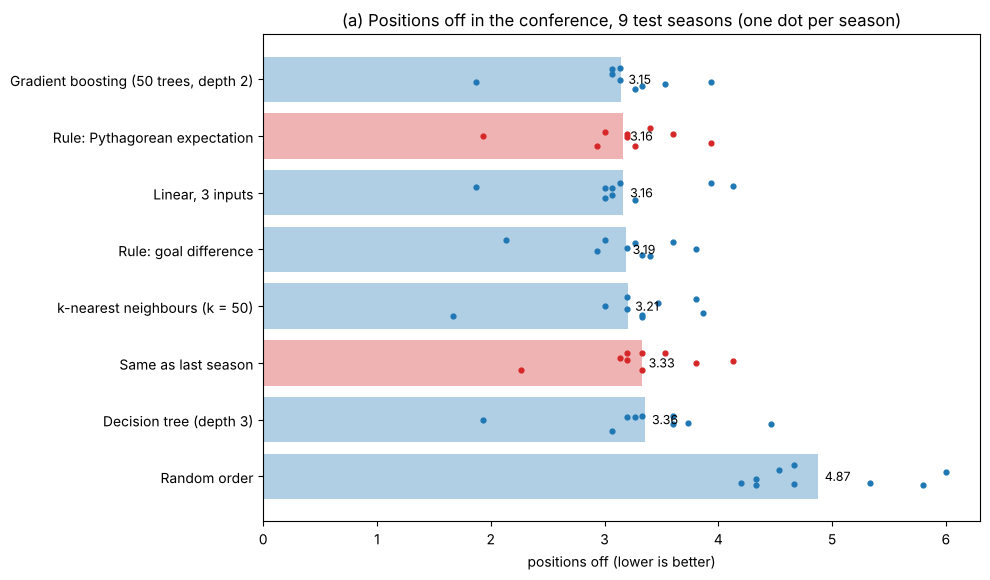

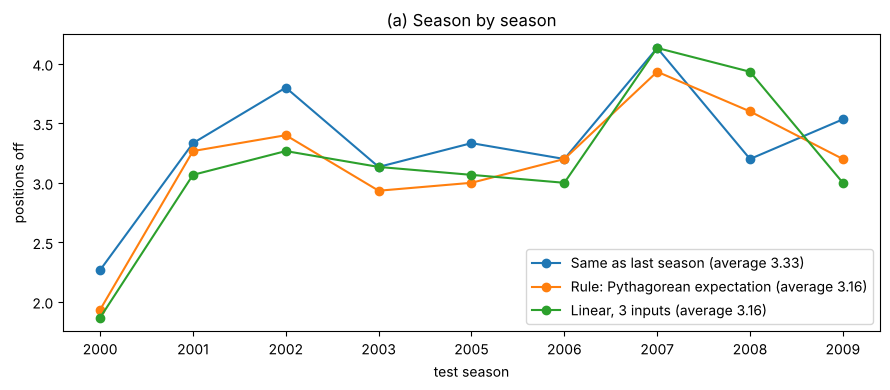

Gradient boosting (50 trees, depth 2)    3.15
Rule: Pythagorean expectation            3.16
Linear, 3 inputs                         3.16
Rule: goal difference                    3.19
k-nearest neighbours (k = 50)            3.21
Same as last season                      3.33
Decision tree (depth 3)                  3.36
Random order                             4.87
dtype: float64

In [2]:
raw = pd.read_csv("../hockey_development_data/Teams.csv")
t = raw[raw["lgID"] == "NHL"].copy()
t["pts_vs_avg"] = (t["Pts"] / t["G"]) / t.groupby("year")["Pts"].transform("sum").div(t.groupby("year")["G"].transform("sum"))
t["gd_per_game"] = (t["GF"] - t["GA"]) / t["G"]
t["pyth"] = t["GF"] ** 2 / (t["GF"] ** 2 + t["GA"] ** 2)
t = t.sort_values(["franchID", "year"])
for col in ["gd_per_game", "pyth"]:
    t[f"last_{col}"] = t.groupby("franchID")[col].shift(1)
t["conf_rank"] = conference_rank(t, true_strength(t))
ct = team_table.merge(t[["year", "franchID", "confID", "pts_vs_avg", "conf_rank", "last_gd_per_game", "last_pyth"]], on=["year", "franchID"], how="left")
before_tests = ct["year"] < seasons[0]
for col in ["last_gd_per_game", "last_pyth"]:
    ct[col] = ct[col].fillna(ct.loc[before_tests, col].quantile(0.15))
F3 = ["last_pts_vs_avg", "avg3_pts_vs_avg", "last_gd_per_game"]
F5 = F3 + ["roster_pts_vs_avg", "roster_goalie_ga_vs_avg"]

def points_model(make, features):
    return lambda tr, te: conference_rank(te, make().fit(tr[features], tr["pts_vs_avg"]).predict(te[features]))

rng = np.random.default_rng(0)
approaches_a = {
    "Random order": lambda tr, te: conference_rank(te, rng.random(len(te))),
    "Same as last season": lambda tr, te: conference_rank(te, te["last_pts_vs_avg"]),
    "Rule: goal difference": lambda tr, te: conference_rank(te, te["last_gd_per_game"]),
    "Rule: Pythagorean expectation": lambda tr, te: conference_rank(te, te["last_pyth"]),
    "Linear, 3 inputs": points_model(LinearRegression, F3),
    "k-nearest neighbours (k = 50)": points_model(lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(50)), F5),
    "Gradient boosting (50 trees, depth 2)": points_model(lambda: GradientBoostingRegressor(n_estimators=50, max_depth=2, learning_rate=0.05,
                                                                                            subsample=0.8, random_state=0), F5),
    "Decision tree (depth 3)": points_model(lambda: DecisionTreeRegressor(max_depth=3, min_samples_leaf=10, random_state=0), F5),
}
res_a = {name: evaluate_by_season(ct, f, mean_conference_rank_error, seasons)["score"] for name, f in approaches_a.items()}
spread_plot(res_a, "(a) Positions off in the conference, 9 test seasons (one dot per season)", "positions off (lower is better)",
            "results_a_all.png", highlight=("Same as last season", "Rule: Pythagorean expectation"))
season_plot({k: res_a[k] for k in ["Same as last season", "Rule: Pythagorean expectation", "Linear, 3 inputs"]},
            "(a) Season by season", "positions off", "results_a_seasons.png")
pd.Series({k: round(v.mean(), 2) for k, v in res_a.items()}).sort_values()

**What it shows (a):** random order is far behind (4.87 positions off); everything that uses last season lands between 3.15 and 3.36. The Pythagorean rule (3.16), which learns nothing, is as good as the best models. The dots show that **one season (2000) is much easier for every approach** (about 1.9–2.3 positions off; 2007 is the hardest, about 3.9–4.1) and that the spread between seasons is bigger than the gap between approaches: that is why no difference is statistically proven.

*Note:* here every model uses one fixed setting (the one the practice test chose most often), so k-nearest neighbours (3.21), gradient boosting (3.15) and the tree (3.36) differ slightly from notebook 03, where the setting was chosen again before each season.

### A real season: 2009, predicted vs actual

The linear model with 3 inputs, trained on 1979–2008, predicts the 2009–10 season. Each arrow goes from the predicted position to the real one; teams on the diagonal were predicted exactly.

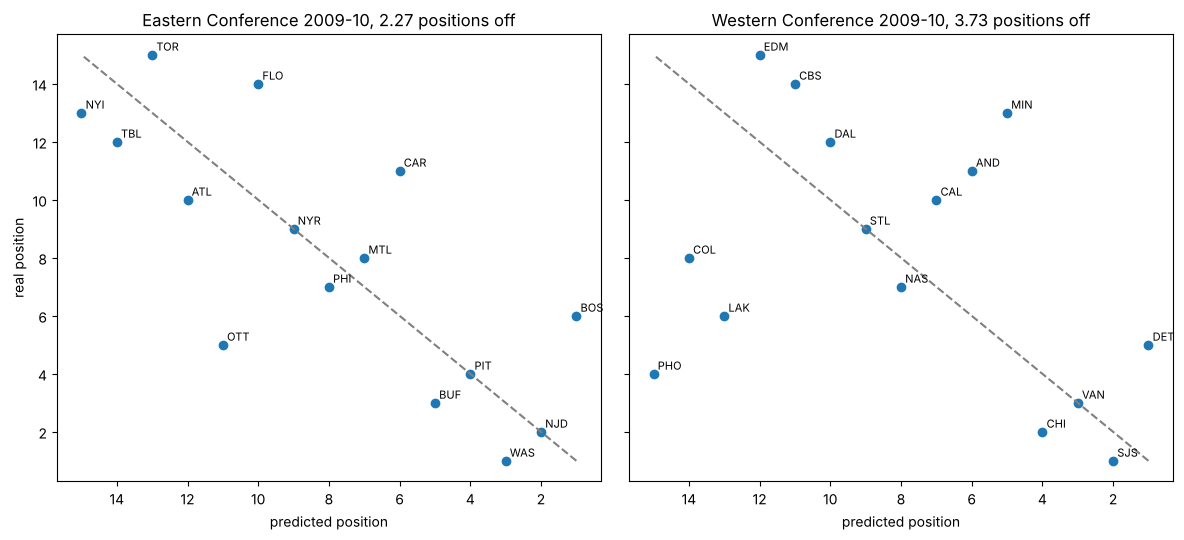

,confID,name,predicted,conf_rank
742,EC,Washington Capitals,3.0,1.0
420,EC,New Jersey Devils,2.0,2.0
75,EC,Buffalo Sabres,5.0,3.0
587,EC,Pittsburgh Penguins,4.0,4.0
497,EC,Ottawa Senators,11.0,5.0
45,EC,Boston Bruins,1.0,6.0
527,EC,Philadelphia Flyers,8.0,7.0
379,EC,Montreal Canadiens,7.0,8.0
480,EC,New York Rangers,9.0,9.0
752,EC,Atlanta Thrashers,12.0,10.0


In [3]:
train, test = ct[ct["year"] < 2009], ct[ct["year"] == 2009].copy()
test["predicted"] = conference_rank(test, LinearRegression().fit(train[F3], train["pts_vs_avg"]).predict(test[F3]))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, conf in zip(axes, ["EC", "WC"]):
    g = test[test["confID"] == conf]
    ax.plot([1, 15], [1, 15], ls="--", color="grey")
    ax.scatter(g["predicted"], g["conf_rank"], color="tab:blue")
    for _, r in g.iterrows():
        ax.annotate(r["tmID"], (r["predicted"], r["conf_rank"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set(xlabel="predicted position", title=f"{'Eastern' if conf == 'EC' else 'Western'} Conference 2009-10, "
                                              f"{np.mean(np.abs(g['predicted'] - g['conf_rank'])):.2f} positions off")
    ax.invert_xaxis(); ax.invert_yaxis()
axes[0].set_ylabel("real position")
plt.tight_layout(); plt.savefig(FIG / "results_a_2009.png", dpi=150, bbox_inches="tight"); plt.show()
test.sort_values(["confID", "conf_rank"])[["confID", "name", "predicted", "conf_rank"]].head(15)

**What it shows:** in 2009–10 the model was 2.27 positions off in the East and 3.73 in the West. It got the top right (Washington 3rd → 1st, New Jersey 2nd → 2nd, Pittsburgh 4th → 4th) but missed teams that changed a lot: Boston (predicted 1st, finished 6th), Ottawa (11th → 5th), Phoenix (15th → 4th, a team that went from weak to strong in one summer), Detroit and Edmonton. These are exactly the in-season changes no pre-season data can see.

## Task (b): coach change

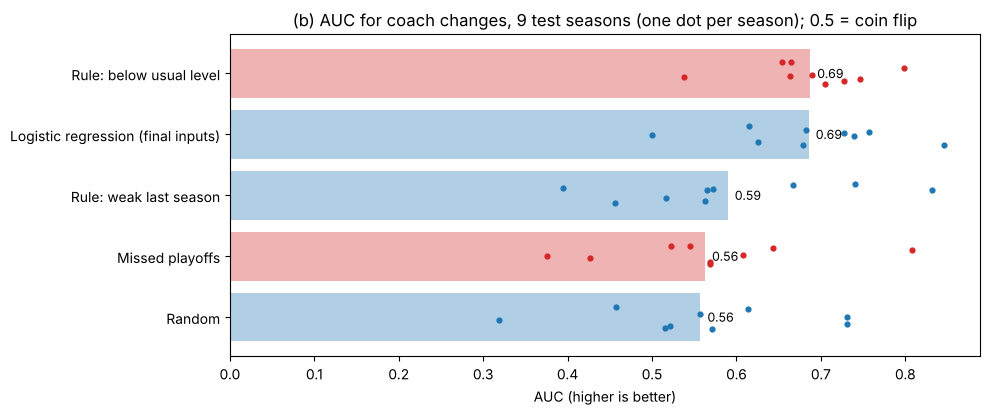

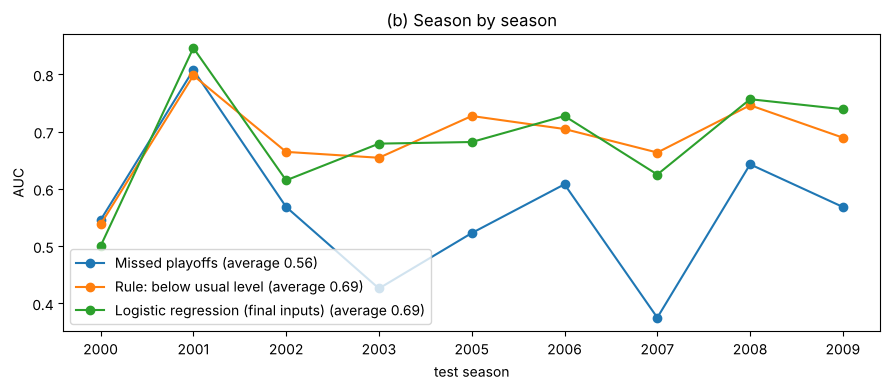

Random                                0.557
Missed playoffs                       0.563
Rule: weak last season                0.590
Logistic regression (final inputs)    0.686
Rule: below usual level               0.687
dtype: float64

In [4]:
coaches_raw = pd.read_csv("../hockey_development_data/Coaches.csv")
tw = pd.read_csv("../data/team_table_with_coaches.csv")
c = coaches_raw[coaches_raw["notes"].isna()].merge(raw[["year", "tmID", "lgID", "franchID"]], on=["year", "tmID", "lgID"])
c = c[c["lgID"] == "NHL"].groupby(["franchID", "year", "coachID"], as_index=False).agg(
    stint=("stint", "min"), g=("g", "sum"), w=("w", "sum"), postg=("postg", "sum"), postw=("postw", "sum"))
last_coach = c.sort_values("stint").groupby(["franchID", "year"]).tail(1).copy()
last_coach["last_coach_po_win_pct"] = (last_coach["postw"] / last_coach["postg"].replace(0, np.nan)).fillna(0)
last_coach["last_coach_reg_win_pct"] = last_coach["w"] / last_coach["g"].replace(0, np.nan)
nhl_seasons = raw[raw["lgID"] == "NHL"][["franchID", "year"]].sort_values(["franchID", "year"])
nhl_seasons["prev_year"] = nhl_seasons.groupby("franchID")["year"].shift(1)
nhl_seasons = nhl_seasons.merge(last_coach.rename(columns={"year": "prev_year"})[["franchID", "prev_year", "last_coach_po_win_pct", "last_coach_reg_win_pct"]],
                                on=["franchID", "prev_year"], how="left")
bt = tw.merge(nhl_seasons[["franchID", "year", "last_coach_po_win_pct", "last_coach_reg_win_pct"]], on=["franchID", "year"], how="left")
bt = bt.sort_values(["franchID", "year"])
bt["pts_vs_usual"] = bt["last_pts_vs_avg"] - bt.groupby("franchID")["last_pts_vs_avg"].transform(lambda s: s.rolling(3, min_periods=1).mean())
bt = bt.dropna(subset=["coach_change"]).sort_values(["year", "franchID"]).reset_index(drop=True)
bt["coach_change"] = bt["coach_change"].astype(int)

F_B = ["coach_seasons", "last_coach_win_pct", "last_pts_vs_avg", "last_season_coaches", "last_made_playoffs", "last_coach_po_win_pct", "pts_vs_usual"]
def logistic_b(train, test):        # "+ below usual" input set, chosen in 6 of 9 seasons by the practice test (notebook 03)
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                          LogisticRegression(class_weight="balanced", max_iter=1000)).fit(train[F_B], train["coach_change"])
    return model.predict_proba(test[F_B])[:, 1]

rng_b = np.random.default_rng(0)
approaches_b = {
    "Random": lambda tr, te: rng_b.random(len(te)),
    "Missed playoffs": lambda tr, te: (te["last_made_playoffs"] == 0).astype(int).values,
    "Rule: weak last season": lambda tr, te: -te["last_pts_vs_avg"].values,
    "Rule: below usual level": lambda tr, te: -te["pts_vs_usual"].values,
    "Logistic regression (final inputs)": logistic_b,
}
res_b = {name: evaluate_by_season(bt, f, coach_auc, seasons)["score"] for name, f in approaches_b.items()}
spread_plot(res_b, "(b) AUC for coach changes, 9 test seasons (one dot per season); 0.5 = coin flip", "AUC (higher is better)",
            "results_b_all.png", lower_is_better=False, highlight=("Missed playoffs", "Rule: below usual level"))
season_plot({k: res_b[k] for k in ["Missed playoffs", "Rule: below usual level", "Logistic regression (final inputs)"]},
            "(b) Season by season", "AUC", "results_b_seasons.png")
pd.Series({k: round(v.mean(), 3) for k, v in res_b.items()}).sort_values()

**What it shows (b):** "missed playoffs" (0.563) is barely above random (0.557). The one-line rule "below usual level" (0.687) and the logistic regression with the final inputs (0.686) are tied, both well above the old guess, and in most seasons. The model's value is the "below usual" idea, not the learning (as found in notebook 03).

### ROC curves and the cut-off trade-off

**ROC curve:** for every possible cut-off, the share of real coach changes caught (y) against the share of teams that kept their coach but were flagged anyway (x). A model that is a coin flip follows the diagonal; the further up and left, the better. The area under the curve is the AUC. All 9 test seasons' predictions are put together.

**Cut-off plot:** for the logistic regression, how recall (changes caught) and precision (flagged teams that really changed) move as the cut-off changes. The practice test chose 0.3–0.5 (notebook 03), favouring recall.

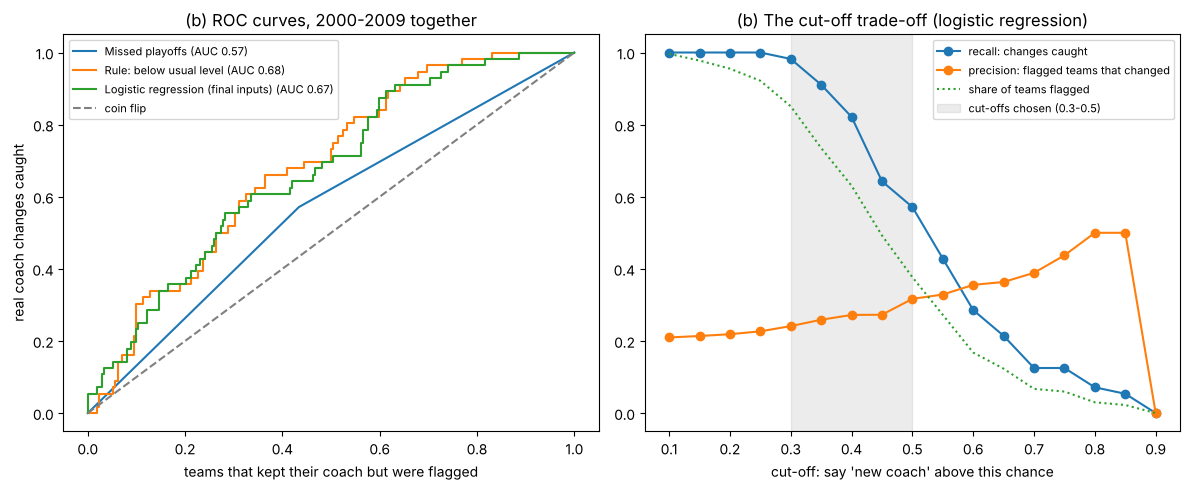

Pooled AUC: {'Missed playoffs': 0.569, 'Rule: below usual level': 0.684, 'Logistic regression (final inputs)': 0.673}


In [5]:
pooled = {name: [] for name in ["Missed playoffs", "Rule: below usual level", "Logistic regression (final inputs)"]}
actual = []
for s in seasons:
    train, test = bt[bt["year"] < s], bt[bt["year"] == s]
    actual.append(test["coach_change"].values)
    for name in pooled:
        pooled[name].append(approaches_b[name](train, test))
actual = np.concatenate(actual)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, preds in pooled.items():
    p = np.concatenate(preds)
    fpr, tpr, _ = roc_curve(actual, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(actual, p):.2f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", label="coin flip")
axes[0].set(xlabel="teams that kept their coach but were flagged", ylabel="real coach changes caught", title="(b) ROC curves, 2000-2009 together")
axes[0].legend(fontsize=8)

p = np.concatenate(pooled["Logistic regression (final inputs)"])
cuts = np.arange(0.1, 0.91, 0.05)
axes[1].plot(cuts, [recall_score(actual, p >= c) for c in cuts], marker="o", label="recall: changes caught")
axes[1].plot(cuts, [precision_score(actual, p >= c, zero_division=0) for c in cuts], marker="o", label="precision: flagged teams that changed")
axes[1].plot(cuts, [np.mean(p >= c) for c in cuts], ls=":", label="share of teams flagged")
axes[1].axvspan(0.3, 0.5, color="grey", alpha=0.15, label="cut-offs chosen (0.3-0.5)")
axes[1].set(xlabel="cut-off: say 'new coach' above this chance", title="(b) The cut-off trade-off (logistic regression)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "results_b_roc_cutoff.png", dpi=150, bbox_inches="tight"); plt.show()
print("Pooled AUC:", {k: round(roc_auc_score(actual, np.concatenate(v)), 3) for k, v in pooled.items()})

**What it shows:** the ROC curves of the rule and the logistic regression lie on top of each other, both clearly above "missed playoffs" (which has only one bend, because it only says yes or no). *Note:* AUC here is computed on all 9 seasons put together (0.67–0.68), which is slightly different from the average of the 9 seasonal AUCs used elsewhere (0.69): putting seasons together also mixes seasons with different change rates.

**The cut-off trade-off:** lowering the cut-off catches more real changes (recall rises to almost 100% at 0.3) but flags more teams, and the share of flagged teams that really change (precision) stays around 0.2–0.3. There is no cut-off that is good at both: that is a property of the problem, not of the model. We chose the low end on purpose, because missing a change is worse than a false alarm (business goal).

## Task (c): penalty minutes

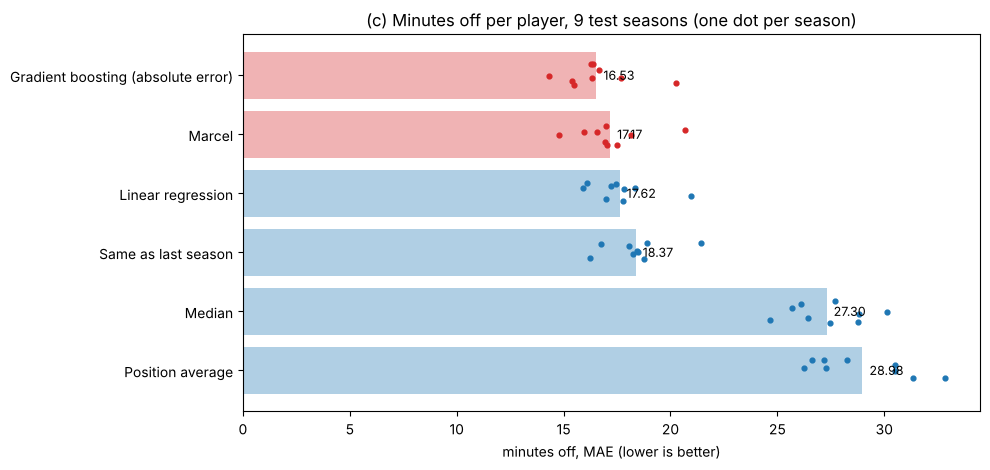

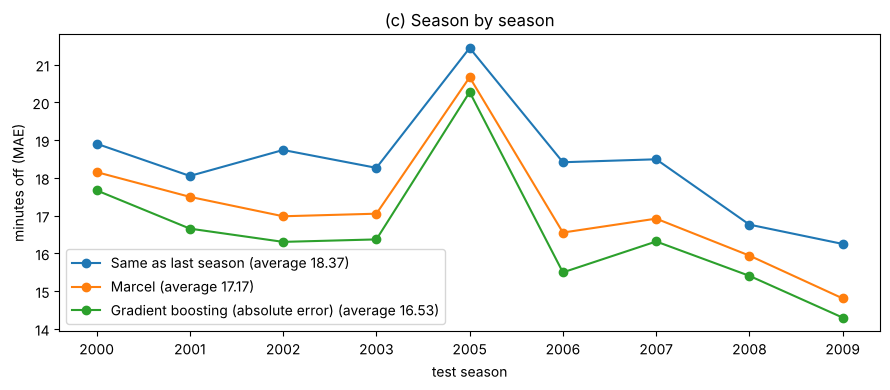

Gradient boosting (absolute error)    16.53
Marcel                                17.17
Linear regression                     17.62
Same as last season                   18.37
Median                                27.30
Position average                      28.98
dtype: float64

In [6]:
pt = pd.read_csv("../data/player_table.csv")
F_C = ["PIM_1", "PIM_2", "PIM_3", "GP_1", "GP_2", "GP_3", "rate_1", "career_rate", "marcel_rate_vs_league",
       "games_guess", "pts_rate_1", "seasons_before", "first_season", "pos_C", "pos_D", "pos_L", "pos_R", "pos_G",
       "team_style_last", "league_rate_last"]
def first_fill(train, test):
    f = train[train["first_season"] == 1]
    return test["pos"].map(f.groupby("pos")["PIM"].median()).fillna(f["PIM"].median())
def boosting_c(train, test):
    m = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_leaf_nodes=7, max_iter=300, min_samples_leaf=40, random_state=0)
    return np.clip(m.fit(train[F_C], train["PIM"]).predict(test[F_C]), 0, None)
approaches_c = {
    "Median": lambda tr, te: np.full(len(te), tr["PIM"].median()),
    "Position average": lambda tr, te: te["pos"].map(tr.groupby("pos")["PIM"].mean()).fillna(tr["PIM"].mean()).values,
    "Same as last season": lambda tr, te: te["PIM_1"].fillna(first_fill(tr, te)).values,
    "Marcel": lambda tr, te: (te["marcel_rate_vs_league"] * te["league_rate_last"] * te["games_guess"]).where(te["first_season"] == 0, first_fill(tr, te)).values,
    "Linear regression": lambda tr, te: np.clip(make_pipeline(StandardScaler(), LinearRegression()).fit(tr[F_C].fillna(-1), tr["PIM"]).predict(te[F_C].fillna(-1)), 0, None),
    "Gradient boosting (absolute error)": boosting_c,
}
res_c = {name: evaluate_by_season(pt, f, pim_mae, seasons)["score"] for name, f in approaches_c.items()}
spread_plot(res_c, "(c) Minutes off per player, 9 test seasons (one dot per season)", "minutes off, MAE (lower is better)",
            "results_c_all.png", highlight=("Marcel", "Gradient boosting (absolute error)"))
season_plot({k: res_c[k] for k in ["Same as last season", "Marcel", "Gradient boosting (absolute error)"]},
            "(c) Season by season", "minutes off (MAE)", "results_c_seasons.png")
pd.Series({k: round(v.mean(), 2) for k, v in res_c.items()}).sort_values()

**What it shows (c):** gradient boosting with absolute error (16.53) is best, and its dots are below Marcel's in every season. Marcel (17.17) beats linear regression (17.62), and both are far ahead of guesses that ignore the player's own history (median 27.3, position 29.0). The season-by-season lines move together: some seasons are harder for everyone.

### Where the final model is right and wrong

Gradient boosting's predictions for all 9 test seasons together:
- **Left:** predicted vs real PIM (dots on the diagonal = exact).
- **Right:** average minutes off by how many minutes the player really got. This shows which players cause the error.

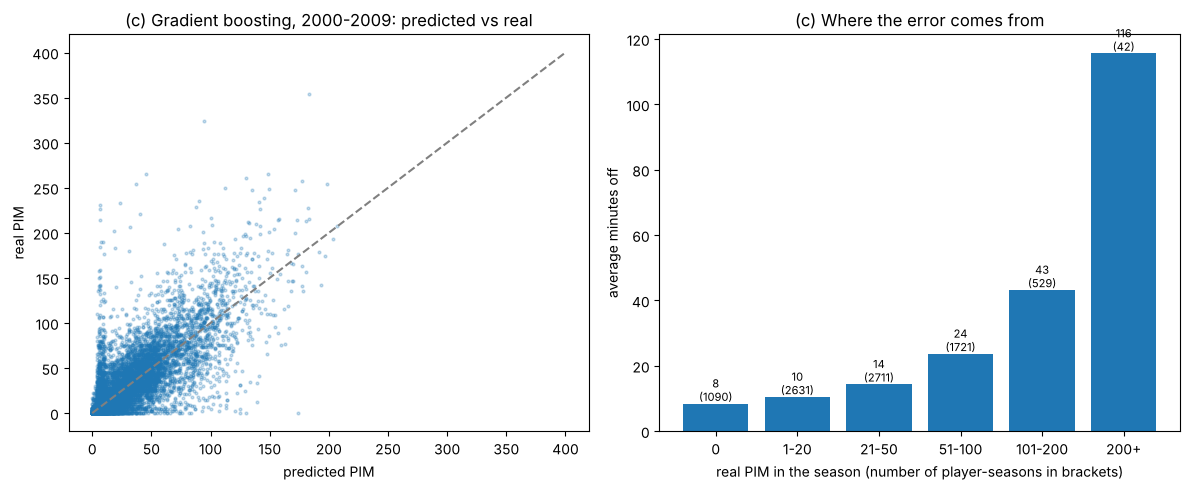

,error,players
band,,
0,8.4,1090
1-20,10.5,2631
21-50,14.4,2711
51-100,23.7,1721
101-200,43.2,529
200+,115.6,42


In [7]:
rows = []
for s in seasons:
    train, test = pt[pt["year"] < s], pt[pt["year"] == s]
    rows.append(test.assign(predicted=boosting_c(train, test)))
pred_c = pd.concat(rows)
pred_c["error"] = (pred_c["predicted"] - pred_c["PIM"]).abs()
pred_c["band"] = pd.cut(pred_c["PIM"], [-1, 0, 20, 50, 100, 200, 500], labels=["0", "1-20", "21-50", "51-100", "101-200", "200+"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(pred_c["predicted"], pred_c["PIM"], s=4, alpha=0.25)
axes[0].plot([0, 400], [0, 400], ls="--", color="grey")
axes[0].set(xlabel="predicted PIM", ylabel="real PIM", title="(c) Gradient boosting, 2000-2009: predicted vs real")
by_band = pred_c.groupby("band", observed=True).agg(error=("error", "mean"), players=("error", "size"))
axes[1].bar(by_band.index.astype(str), by_band["error"], color="tab:blue")
for i, (e, n) in enumerate(zip(by_band["error"], by_band["players"])):
    axes[1].text(i, e, f"{e:.0f}\n({n})", ha="center", va="bottom", fontsize=8)
axes[1].set(xlabel="real PIM in the season (number of player-seasons in brackets)", ylabel="average minutes off", title="(c) Where the error comes from")
plt.tight_layout(); plt.savefig(FIG / "results_c_errors.png", dpi=150, bbox_inches="tight"); plt.show()
by_band.round(1)

**What it shows:** the error grows with the real PIM. Players with 0–20 minutes are 8–10 minutes off, players with 101–200 minutes are 43 off, and the 42 player-seasons above 200 minutes are 116 off on average. The model **never predicts more than about 210 minutes**: trained on absolute error, it aims at the typical player and does not chase the few enforcers. That is the trade-off we chose (it gives the lowest MAE), and it is also its limit: it cannot spot a new enforcer before he plays.